In [40]:
import pandas as pd
import matplotlib.pyplot as pt
import seaborn as sn

### Telecharger data

In [7]:
data = pd.read_csv("../data/orig/student_mental_health.csv")

In [8]:
data.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [ ]:
print("le nombre de lignes est ",data.shape[0],"et le nombre de columns est :",data.shape[1])

le nombre des lignes est  2000 et le nombre des columns est : 17


In [12]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [13]:
data.nunique()

Student_ID                        2000
Age                                 13
Gender                               3
Year_of_Study                        5
Sleep_Hours                         66
Study_Hours_Per_Week               284
GPA                                182
Social_Media_Hours                  71
Screen_Time_Hours                   95
Physical_Activity                    3
Financial_Stress                    87
Family_Support                      82
Attendance_Rate                    313
Part_Time_Job                        2
Diet_Quality                         3
Previous_Mental_Health_History       2
Mental_Health_Risk                   3
dtype: int64

In [27]:
data.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [16]:
data.isnull().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [23]:
print("On a :",data.isna().sum().sum(),"valeurs manquants")

On a : 419 valeurs manquants


In [24]:
data[data.duplicated()]
print(" les doublons: ",data.duplicated().sum())

 les doublons:  0


###  les anomalies

In [ ]:
# D'apres l'analyse descriptive (describe()), aucune anomalie evidente ni incohérence logique n'a été détectée dans les variables

### les valeurs aberrantes

In [36]:
numeric_variables=data.select_dtypes(include='number').columns

for col in numeric_variables:
    q1=data[col].quantile(0.25)
    q3=data[col].quantile(0.75)
    iqr= q3-q1
    l=q1- 1.5 *iqr
    u=q3 +1.5 *iqr

    outliers = data[(data[col] < l) | (data[col] > u)]
    print(f"{col} : {len(outliers)} outliers")

Age : 4 outliers
Year_of_Study : 0 outliers
Sleep_Hours : 2 outliers
Study_Hours_Per_Week : 7 outliers
GPA : 9 outliers
Social_Media_Hours : 20 outliers
Screen_Time_Hours : 7 outliers
Financial_Stress : 0 outliers
Family_Support : 0 outliers
Attendance_Rate : 12 outliers


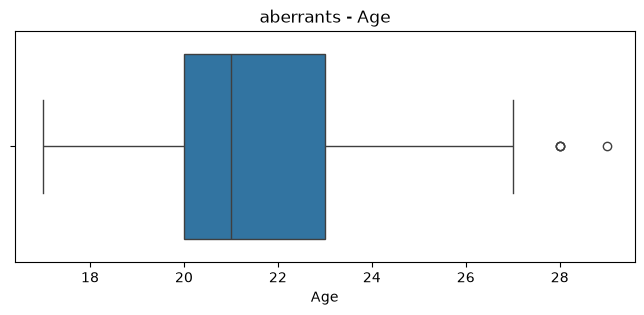

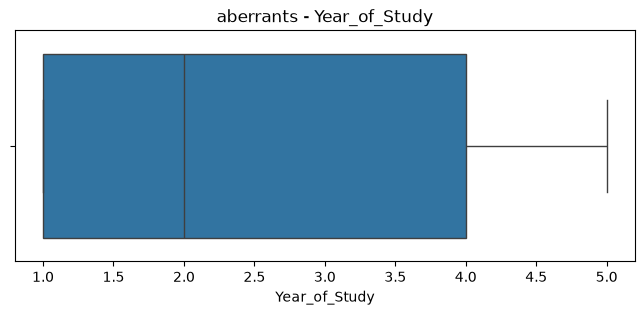

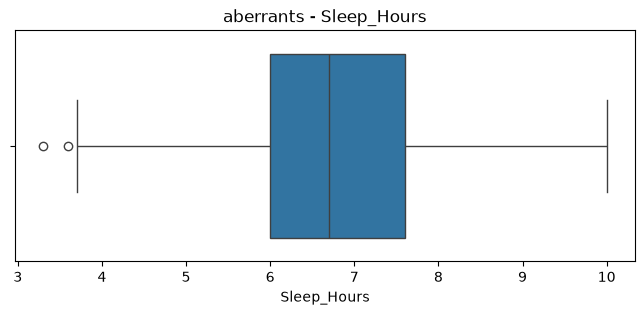

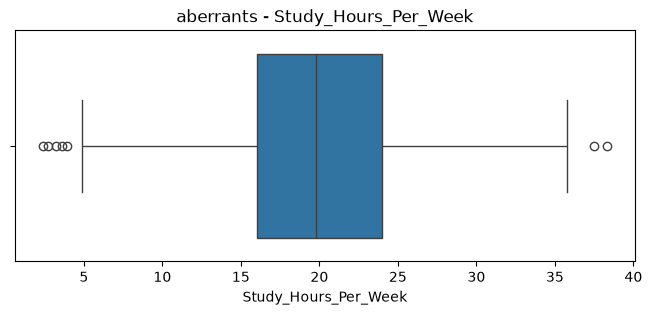

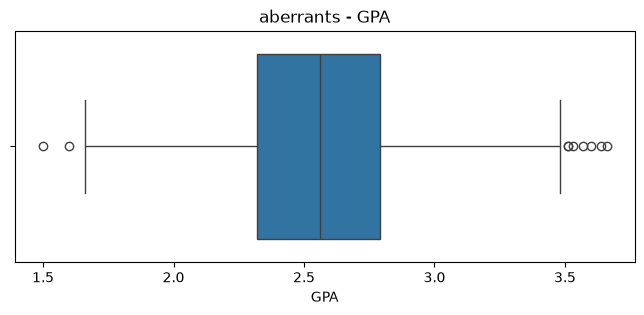

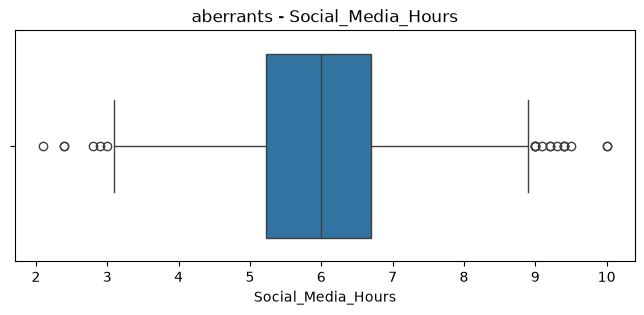

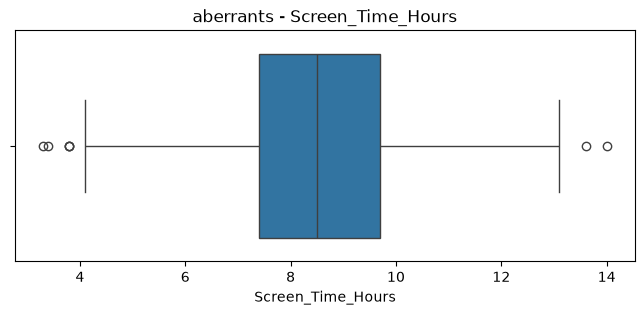

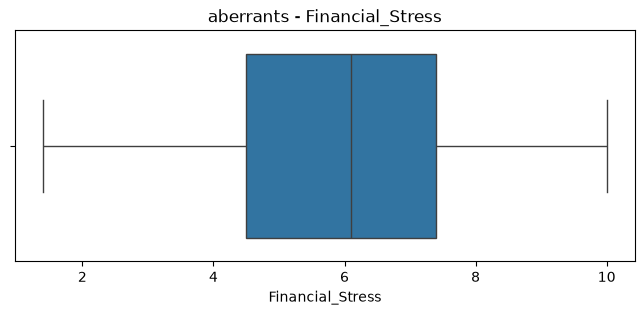

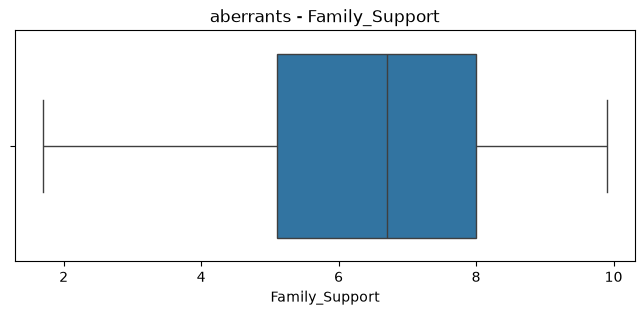

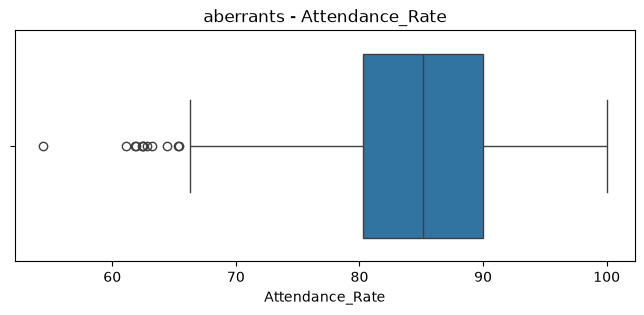

In [41]:
for col  in numeric_variables:
    pt.figure(figsize=(8,3))
    sn.boxplot(x=data[col])
    pt.title(f"aberrants - {col}")
    pt.show()